In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Import modules from the project root
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.stochastic_geometry import random_height_profile
from src.layer_mesh import build_layer_mesh
from src.mesh_quality import evaluate_mesh_quality

from sfepy.discrete.fem import Mesh, FEDomain, Field
from sfepy.discrete import FieldVariable, Material, Integral, Equation, Equations, Problem
from sfepy.discrete.conditions import EssentialBC, Conditions
from sfepy.mechanics.matcoefs import stiffness_from_youngpoisson
from sfepy.terms import Term
from sfepy.solvers.ls import ScipyDirect
from sfepy.solvers.nls import Newton

install jax and jaxlib to use terms_jax.py!
sfepy: WARNING: module /Users/zewei/miniconda3/envs/biofilm-fem/lib/python3.13/site-packages/sfepy/terms/terms_jax.py cannot be imported!
sfepy: reason:
 No module named 'jax'


In [2]:
# Geometry parameters (μm)
L = 500.0
nx = 501

x = np.linspace(0, L, nx)

h = random_height_profile(
    x,
    mean_height=80.0,
    roughness=15.0,
    n_features=10,
    min_height=5.0,
    rng=np.random.default_rng(0)
)

# Generate triangular mesh
points_um, triangles, boundaries = build_layer_mesh(
    x, h, ny=60
)

# Convert to SI units
UM = 1e-6
points_m = points_um * UM

In [3]:
mesh = Mesh.from_data(
    "stochastic_biofilm",
    points_m,
    None,
    [triangles.astype(np.int32)],
    [np.zeros(len(triangles), dtype=np.int32)],
    ["2_3"]
)

domain = FEDomain("biofilm_domain", mesh)

omega = domain.create_region("Omega", "all")

base = domain.create_region(
    "Base",
    "vertices in (y < 1e-10)",
    "facet"
)

def select_top(coors, domain=None):
    expected_height = np.interp(
        coors[:, 0],
        x * UM,
        h * UM
    )

    return np.where(
        np.abs(coors[:, 1] - expected_height) < 1e-10
    )[0]

top = domain.create_region(
    "Top",
    "vertices by select_top",
    "facet",
    functions={"select_top": select_top}
)

print("Nodes:", mesh.n_nod)
print("Elements:", mesh.n_el)
print("Base vertices:", len(base.vertices))
print("Top vertices:", len(top.vertices))

Nodes: 30561
Elements: 60000
Base vertices: 501
Top vertices: 501


## 1. Defining the Displacement Field

### Physical interpretation

The objective of structural finite-element analysis (FEM) is to determine how the biofilm deforms when subjected to external mechanical loading.

Every point within the biofilm can move in two directions:

- **Horizontal displacement**, $u_x(x,y)$
- **Vertical displacement**, $u_y(x,y)$

The displacement field is therefore represented by the vector:

$$
\mathbf{u}(x,y)=
\begin{bmatrix}
u_x(x,y)\\
u_y(x,y)
\end{bmatrix}
$$

Rather than solving for displacement at infinitely many points, FEM divides the biofilm into triangular elements and approximates displacement using a finite number of unknowns.

### Finite-element approximation

Within each triangular element, the displacement field is approximated as:

$$
\mathbf{u}(x,y)
\approx
\sum_{i=1}^{n}N_i(x,y)\mathbf{u}_i
$$

where:

- $N_i(x,y)$: Shape function associated with node $i$.
- $\mathbf{u}_i$: Unknown displacement vector at node $i$.
- $n$: Number of displacement nodes associated with the element.

For **first-order triangular elements (P1)**, each triangle has three nodes, and the shape functions are linear.

Consequently, displacement varies linearly within each triangle.

### SfePy implementation

We create a vector-valued finite-element field using:

`Field.from_args()`

The arguments specify:

- `"displacement"`: Name of the field.
- `np.float64`: Numerical precision.
- `"vector"`: Two displacement components per node.
- `omega`: The biofilm domain.
- `approx_order=1`: First-order finite elements.

Two variables are then defined:

**Unknown variable (`u`)**

Represents the displacement field that the solver must calculate.

**Test variable (`v`)**

Used to formulate the weak form of the governing elasticity equations. It represents an arbitrary admissible virtual displacement.

The weak form allows FEM to convert differential equations into a system of algebraic equations.

### Degrees of freedom

Our mesh contains 30,561 nodes.

Since each node has two displacement components:

$$
N_{\mathrm{DOF}}=2(30561)=61122
$$

These are the displacement degrees of freedom before applying boundary constraints.

In [4]:
field = Field.from_args(
    "displacement",
    np.float64,
    "vector",
    omega,
    approx_order=1
)

u = FieldVariable(
    "u",
    "unknown",
    field
)

v = FieldVariable(
    "v",
    "test",
    field,
    primary_var_name="u"
)

print("Number of nodes:", field.n_nod)
print("Displacement DOFs:", field.n_nod * field.n_components)

Number of nodes: 30561
Displacement DOFs: 61122


## 2. Defining the Material Properties

### Physical assumptions

We initially approximate the biofilm as a **homogeneous, isotropic, linearly elastic material**.

This means:

1. **Homogeneous:** Mechanical properties are constant throughout the biofilm.
2. **Isotropic:** Mechanical properties are independent of direction.
3. **Linearly elastic:** Stress is proportional to strain, and deformation is reversible.
4. **Small-strain:** Changes in geometry are sufficiently small for linearized strain theory.

The material is characterized by two parameters:

- **Young's modulus**, $E$: Resistance to elastic deformation.
- **Poisson's ratio**, $\nu$: Relationship between longitudinal and transverse deformation.

For our initial simulation, we use illustrative parameters:

$$
E=64\ \mathrm{Pa}
$$

$$
\nu=0.3
$$

These are not experimentally measured properties of our engineered *B. subtilis* biofilm.

### Stress–strain relationship

Under linear elasticity, stress and strain are related through Hooke's law:

$$
\boxed{
\boldsymbol{\sigma}=\mathbf{D}\boldsymbol{\varepsilon}
}
$$

For a two-dimensional problem, we express the in-plane stress and engineering strain vectors as:

$$
\boldsymbol{\sigma}=
\begin{bmatrix}
\sigma_{xx}\\
\sigma_{yy}\\
\tau_{xy}
\end{bmatrix}
$$

$$
\boldsymbol{\varepsilon}=
\begin{bmatrix}
\varepsilon_{xx}\\
\varepsilon_{yy}\\
\gamma_{xy}
\end{bmatrix}
$$

where:

$$
\gamma_{xy}=2\varepsilon_{xy}
$$

### Plane-strain assumption

We use a plane-strain formulation:

$$
\varepsilon_{zz}=0
$$

This approximates a two-dimensional cross-section of a structure constrained against deformation in the out-of-plane direction.

For isotropic linear elasticity, the plane-strain constitutive matrix is:

$$
\boxed{
\mathbf{D}=
\frac{E}{(1+\nu)(1-2\nu)}
\begin{bmatrix}
1-\nu & \nu & 0\\
\nu & 1-\nu & 0\\
0 & 0 & \frac{1-2\nu}{2}
\end{bmatrix}
}
$$

Therefore:

$$
\begin{bmatrix}
\sigma_{xx}\\
\sigma_{yy}\\
\tau_{xy}
\end{bmatrix}
=
\mathbf{D}
\begin{bmatrix}
\varepsilon_{xx}\\
\varepsilon_{yy}\\
\gamma_{xy}
\end{bmatrix}
$$

**Important:** Plane strain assumes zero out-of-plane strain, not zero out-of-plane stress. In general, $\sigma_{zz}\neq0$.

### SfePy implementation

The function:

`stiffness_from_youngpoisson(2, E, nu, plane="strain")`

constructs the plane-strain elastic stiffness matrix $\mathbf{D}$.

We then define:

`Material("biofilm", D=D)`

This makes the material's constitutive properties available to the FEM equations.

### Mechanical failure threshold

We also define an illustrative effective strength threshold:

$$
\sigma_t=1.0\ \mathrm{Pa}
$$

However, $\sigma_t$ is **not part of the linear-elastic constitutive matrix**.

It will be used during postprocessing to identify regions where calculated stresses exceed an assumed mechanical failure criterion.

This identifies potential mechanical vulnerability, not actual fracture or detachment.

In [5]:
# Illustrative material properties
E = 64.0       # Young's modulus (Pa)
nu = 0.3       # Poisson's ratio

# Plane-strain elastic stiffness matrix
D = stiffness_from_youngpoisson(
    2,
    E,
    nu,
    plane="strain"
)

material = Material(
    "biofilm",
    D=D
)

print("Elastic stiffness matrix:")
print(D)

Elastic stiffness matrix:
[[86.15384615 36.92307692  0.        ]
 [36.92307692 86.15384615  0.        ]
 [ 0.          0.         24.61538462]]


## 3. Defining the Fixed-Substrate Boundary Condition

### Physical interpretation

The biofilm is assumed to be firmly attached to a stationary substrate.

Consequently, points along the attachment boundary cannot move horizontally or vertically.

The substrate is located at:

$$
y=0
$$

We therefore prescribe:

$$
\boxed{
u_x(x,0)=0
}
$$

$$
\boxed{
u_y(x,0)=0
}
$$

These are known as **Dirichlet boundary conditions**, or essential boundary conditions in FEM.

They specify the displacement directly rather than specifying an applied force.

### SfePy implementation

We use:

`EssentialBC("fix_base", base, {"u.all": 0.0})`

where:

- `"fix_base"`: Name of the boundary condition.
- `base`: Previously defined region representing the biofilm–substrate interface.
- `"u.all"`: Both horizontal and vertical displacement components.
- `0.0`: Prescribed displacement in metres.

### Extension to bellows-induced deformation

This fixed-substrate assumption is appropriate for our initial numerical baseline.

However, the ISS wastewater tank contains metallic bellows that expand and contract.

Biofilm attached to the bellows may experience deformation as the underlying metal surface moves.

In a future iteration, we can replace the fixed condition with a prescribed displacement field:

$$
\boxed{
\mathbf{u}(x,0)=
\mathbf{u}_{\mathrm{bellows}}(x)
}
$$

For example, a simplified horizontal stretching condition could be:

$$
u_x(x,0)=\varepsilon_{\mathrm{sub}}x
$$

$$
u_y(x,0)=0
$$

where $\varepsilon_{\mathrm{sub}}$ represents an illustrative strain imposed by the substrate.

A more realistic model would account for changes in the curvature and opening angle of the V-shaped bellows convolutions.

**Note:** Bellows deformation is not yet implemented. The current model assumes a stationary, rigid substrate.

In [6]:
fix_base = EssentialBC(
    "fix_base",
    base,
    {"u.all": 0.0}
)

print("Fixed-base boundary condition created.")

Fixed-base boundary condition created.


## 4. Summary of the Structural FEM Setup

We have now defined the three fundamental components of our structural FEM model.

### 1. Geometry

The biofilm occupies a two-dimensional domain:

$$
\Omega=
\left\{
(x,y):
0\leq x\leq L,\quad
0\leq y\leq h(x)
\right\}
$$

where $h(x)$ is a stochastically generated biofilm height profile.

The domain has been discretized into triangular finite elements.

### 2. Material behaviour

We assume homogeneous, isotropic, small-strain linear elasticity:

$$
\boldsymbol{\sigma}
=
\mathbf{D}\boldsymbol{\varepsilon}
$$

Strain is related to displacement through:

$$
\boxed{
\boldsymbol{\varepsilon}
=
\frac{1}{2}
\left(
\nabla\mathbf{u}
+
\nabla\mathbf{u}^{T}
\right)
}
$$

### 3. Boundary conditions

The biofilm is initially attached to a stationary substrate:

$$
\mathbf{u}(x,0)=\mathbf{0}
$$

The upper surface remains available for externally applied mechanical loading.

### Governing equilibrium equation

For static mechanical equilibrium:

$$
\boxed{
\nabla\cdot\boldsymbol{\sigma}+\mathbf{f}=\mathbf{0}
}
$$

where $\mathbf{f}$ represents body force per unit volume.

We initially neglect body forces:

$$
\mathbf{f}=\mathbf{0}
$$

Therefore:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf{0}
$$

Combining equilibrium, the strain–displacement relationship, and Hooke's law gives the governing equations for the unknown displacement field.

After discretization, FEM produces a system of algebraic equations:

$$
\boxed{
\mathbf{K}\mathbf{U}=\mathbf{F}
}
$$

where:

- $\mathbf{K}$: Global stiffness matrix.
- $\mathbf{U}$: Unknown nodal displacement vector.
- $\mathbf{F}$: External force vector.

The next step is to define the applied surface traction and assemble this system using SfePy.

Once displacement has been calculated, we can derive the strain and stress fields and evaluate mechanical vulnerability.

## 5. Defining External Mechanical Loading

### Physical interpretation

The biofilm is subjected to external mechanical loading, which causes it to deform.

In our initial model, we approximate this loading as a uniform horizontal traction acting on the exposed biofilm surface.

**Traction** is force per unit area:

$$
\mathbf{t}=\frac{d\mathbf{F}}{dA}
$$

Its unit is pascals ($\mathrm{Pa}=\mathrm{N/m^2}$).

We prescribe:

$$
\boxed{
\mathbf{t}=
\begin{bmatrix}
t_x\\
t_y
\end{bmatrix}
=
\begin{bmatrix}
0.01\\
0
\end{bmatrix}
\ \mathrm{Pa}
}
$$

This means the biofilm experiences a horizontal force directed toward positive $x$.

The value $0.01$ Pa is illustrative. We deliberately use a smaller load than our previous $0.3$ Pa reference to reduce the likelihood of violating the small-strain assumption.

### Important distinction: Traction versus pressure

Traction is a vector describing the force per unit area acting on a surface.

Fluid pressure, however, acts normal to the surface.

For a fluid pressure $p$, the corresponding pressure traction on a solid surface is:

$$
\mathbf{t}_{p}=-p\mathbf{n}
$$

where $\mathbf{n}$ is the outward unit normal of the solid, using the appropriate fluid–solid stress convention.

Therefore, prescribing a uniform horizontal traction on our irregular surface is **not equivalent to applying uniform fluid pressure**.

In future iterations, CFD will calculate both pressure and viscous contributions to the actual fluid traction.

### Total applied force

Because our biofilm surface is irregular, its actual length exceeds its horizontal projection.

For a surface described by $y=h(x)$:

$$
ds=\sqrt{1+\left(\frac{dh}{dx}\right)^2}\,dx
$$

Assuming unit out-of-plane depth $b=1$ m, the total horizontal force is:

$$
F_x=t_x b\int_0^L
\sqrt{1+[h'(x)]^2}\,dx
$$

This distinction matters because the same traction applied to surfaces with different roughness can produce different total forces.

We will account for this when comparing different biofilm geometries.

In [7]:
# Illustrative horizontal traction (Pa)
traction_x = 0.01
traction_y = 0.0

traction = Material(
    "traction",
    val=np.array([[traction_x], [traction_y]])
)

print("Applied traction:", traction_x, traction_y, "Pa")

Applied traction: 0.01 0.0 Pa


## 6. Constructing the FEM Equilibrium Equations

### Governing equation

The biofilm must satisfy static mechanical equilibrium:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf{0}
$$

where $\boldsymbol{\sigma}$ is the internal stress tensor.

### Weak formulation

Instead of solving the differential equation directly, FEM expresses equilibrium through the principle of virtual work.

For any admissible virtual displacement $\mathbf{v}$:

$$
\boxed{
\int_{\Omega}
\boldsymbol{\varepsilon}(\mathbf{v})^T
\mathbf{D}
\boldsymbol{\varepsilon}(\mathbf{u})
\,d\Omega
=
\int_{\Gamma_t}
\mathbf{v}\cdot\mathbf{t}
\,d\Gamma
}
$$

where:

- $\Omega$: Biofilm domain.
- $\Gamma_t$: Boundary where traction is applied.
- $\mathbf{u}$: Unknown displacement.
- $\mathbf{v}$: Test function.
- $\mathbf{D}$: Elastic stiffness matrix.
- $\mathbf{t}$: Prescribed surface traction.

The left-hand side represents internal virtual work.

The right-hand side represents external virtual work.

### Finite-element discretization

Within each triangular element, displacement is approximated using shape functions:

$$
\mathbf{u}(x,y)\approx\mathbf{N}(x,y)\mathbf{U}_e
$$

Strain is calculated using:

$$
\boldsymbol{\varepsilon}=\mathbf{B}\mathbf{U}_e
$$

where $\mathbf{B}$ contains derivatives of the shape functions.

Substituting these expressions into the weak form gives:

$$
\boxed{
\mathbf{K}_e=
\int_{\Omega_e}
\mathbf{B}^T\mathbf{D}\mathbf{B}
\,d\Omega
}
$$

and the element force vector:

$$
\boxed{
\mathbf{F}_e=
\int_{\Gamma_{t,e}}
\mathbf{N}^T\mathbf{t}
\,d\Gamma
}
$$

SfePy assembles the element contributions into the global system:

$$
\boxed{
\mathbf{K}\mathbf{U}=\mathbf{F}
}
$$

After applying the fixed-substrate boundary conditions, this system can be solved for the unknown nodal displacements.

In [8]:
# Numerical integration
integral = Integral("i", order=2)

# Internal elastic forces
term_elastic = Term.new(
    "dw_lin_elastic(biofilm.D, v, u)",
    integral,
    omega,
    biofilm=material,
    v=v,
    u=u
)

# External surface traction
term_traction = Term.new(
    "dw_surface_ltr(traction.val, v)",
    integral,
    top,
    traction=traction,
    v=v
)

# Internal forces = external forces
equation = Equation(
    "elastic_equilibrium",
    term_elastic - term_traction
)

equations = Equations([equation])

print("Elasticity equations created successfully.")

Elasticity equations created successfully.


## 7. Solving the Structural FEM Problem

After assembling the finite-element equations, we obtain:

$$
\mathbf{K}\mathbf{U}=\mathbf{F}
$$

where $\mathbf{K}$ is the global stiffness matrix and $\mathbf{F}$ is the external force vector.

The fixed-substrate boundary condition removes rigid-body motion and provides a reference for the displacement field.

We solve the resulting linear system numerically.

The solution gives the horizontal and vertical displacement at every finite-element node.

From these displacements, we can subsequently calculate:

1. Strain distributions.
2. Internal stress distributions.
3. Von Mises equivalent stress.
4. Regions exceeding an assumed mechanical strength threshold.

Before interpreting the results, we must verify force balance, numerical convergence, and whether the calculated strains remain sufficiently small for linear elasticity.

In [9]:
# Create FEM problem
problem = Problem(
    "biofilm_elasticity",
    equations=equations
)

# Apply fixed-base boundary condition
problem.time_update(ebcs=Conditions([fix_base]))

# Linear system solver
ls = ScipyDirect({})

# Nonlinear solver interface
nls = Newton(
    {"i_max": 1, "eps_a": 1e-10},
    lin_solver=ls
)

problem.set_solver(nls)

# Solve
state = problem.solve()

print("Structural FEM solve completed.")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.01 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy:     traction
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 2.356466e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 3.168807e-19 (rel: 1.344729e-12)


Warning: VTK requires 3D vectors, but 2D vectors given. Appending 0 third component to u.

sfepy: solved in 1 steps in 0.28 seconds
Structural FEM solve completed.


## 8. Visualizing the Displacement Field

The structural FEM solver calculates the displacement vector at each node:

$$
\mathbf{u}(x,y)=
\begin{bmatrix}
u_x(x,y)\\
u_y(x,y)
\end{bmatrix}
$$

The displacement magnitude is:

$$
\boxed{
|\mathbf{u}|=\sqrt{u_x^2+u_y^2}
}
$$

This measures the total distance that each point moves from its original position.

We visualize the displacement magnitude to identify regions experiencing the largest deformation.

Because the simulation uses small-strain linear elasticity, the resulting displacement must be checked against the dimensions of the biofilm before interpreting the solution quantitatively.

Maximum displacement: 0.077077 μm
Displacement shape: (30561, 2)
Mesh nodes: 30561
Maximum displacement (μm): 0.07707676645887283


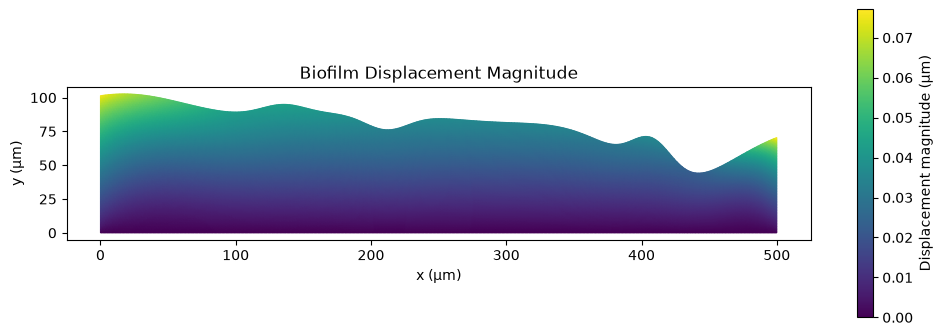

In [10]:
# Extract nodal displacement
u_nodal = state["u"]().reshape(-1, 2)

# Calculate displacement magnitude
u_magnitude = np.linalg.norm(u_nodal, axis=1)

# Convert to micrometres for visualization
u_um = u_nodal / UM
u_magnitude_um = u_magnitude / UM

print(f"Maximum displacement: {u_magnitude_um.max():.6f} μm")

u_nodal = state["u"]().reshape(-1, 2)

print("Displacement shape:", u_nodal.shape)
print("Mesh nodes:", mesh.n_nod)
print("Maximum displacement (μm):",
      np.linalg.norm(u_nodal, axis=1).max() / UM)

# Plot displacement magnitude
fig, ax = plt.subplots(figsize=(12, 4))

plot = ax.tripcolor(
    points_um[:, 0],
    points_um[:, 1],
    triangles,
    u_magnitude_um,
    shading="gouraud",
    cmap="viridis"
)

fig.colorbar(
    plot,
    ax=ax,
    label="Displacement magnitude (μm)"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Biofilm Displacement Magnitude")
ax.set_aspect("equal")

plt.show()

## 9. Calculating the Strain Field

The displacement field describes how far each point moves, while the strain field describes how much the material deforms locally.

For small deformations, the strain tensor is:

$$
\boldsymbol{\varepsilon}
=
\frac12
\left(
\nabla\mathbf u+\nabla\mathbf u^T
\right)
$$

For a two-dimensional biofilm:

$$
\boldsymbol{\varepsilon}=
\begin{bmatrix}
\frac{\partial u_x}{\partial x}
&
\frac12\left(\frac{\partial u_x}{\partial y}+\frac{\partial u_y}{\partial x}\right)
\\
\frac12\left(\frac{\partial u_x}{\partial y}+\frac{\partial u_y}{\partial x}\right)
&
\frac{\partial u_y}{\partial y}
\end{bmatrix}
$$

We calculate strain within each triangular element using the derivatives of the finite-element displacement field.

This allows us to verify whether the small-strain approximation used in our linear-elastic model is appropriate.

In [11]:
strain = problem.evaluate(
    "ev_cauchy_strain.i.Omega(u)",
    mode="el_avg",
    integrals={"i": integral}
)

print("Strain shape:", strain.shape)

strain_elements = strain.reshape(-1, 3)

print("First five element strains:")
print(strain_elements[:5])

sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
Strain shape: (60000, 1, 3, 1)
First five element strains:
[[ 0.          0.00071168  0.00073115]
 [-0.00035596  0.00101987  0.00041994]
 [ 0.          0.00071168  0.00073115]
 [-0.00015803  0.00061653  0.00047675]
 [ 0.          0.00051474  0.00054623]]


## 10. Verifying the Small-Strain Assumption

Our structural FEM assumes small-strain linear elasticity.

The strain tensor is:

$$
\boldsymbol{\varepsilon}=
\begin{bmatrix}
\varepsilon_{xx} & \varepsilon_{xy}\\
\varepsilon_{xy} & \varepsilon_{yy}
\end{bmatrix}
$$

The principal strains are the eigenvalues of this tensor. They represent the maximum and minimum normal strains at a point, considering all possible directions.

For a two-dimensional strain tensor:

$$
\boxed{
\varepsilon_{1,2}
=
\frac{\varepsilon_{xx}+\varepsilon_{yy}}{2}
\pm
\sqrt{
\left(\frac{\varepsilon_{xx}-\varepsilon_{yy}}{2}\right)^2
+\varepsilon_{xy}^2
}
}
$$

We calculate the largest absolute principal strain across all elements to assess whether the predicted deformation is sufficiently small for our linearized model.

This is a necessary diagnostic, although small strain alone does not guarantee small rotations or complete validity of linear elasticity.

In [12]:
# Extract strain components
exx = strain_elements[:, 0]
eyy = strain_elements[:, 1]
exy = strain_elements[:, 2]

# Calculate principal strains
mean_strain = (exx + eyy) / 2

radius = np.sqrt(
    ((exx - eyy) / 2)**2 + exy**2
)

eps1 = mean_strain + radius
eps2 = mean_strain - radius

# Maximum absolute principal strain
max_principal_strain = np.max(
    np.maximum(np.abs(eps1), np.abs(eps2))
)

print(f"Maximum absolute principal strain: {max_principal_strain:.6f}")
print(f"Maximum absolute principal strain: {max_principal_strain * 100:.4f}%")

Maximum absolute principal strain: 0.001273
Maximum absolute principal strain: 0.1273%


## 11. Calculating the Stress Tensor

Having calculated the strain field, we can determine the internal stresses using Hooke's law:

$$
\boldsymbol{\sigma}=\mathbf D\boldsymbol{\varepsilon}
$$

For an isotropic, linearly elastic material under plane strain:

$$
\varepsilon_{zz}=0
$$

However, this does not imply that $\sigma_{zz}=0$.

The three-dimensional stress tensor is:

$$
\boldsymbol{\sigma}=
\begin{bmatrix}
\sigma_{xx} & \tau_{xy} & 0\\
\tau_{xy} & \sigma_{yy} & 0\\
0 & 0 & \sigma_{zz}
\end{bmatrix}
$$

The out-of-plane stress is:

$$
\boxed{
\sigma_{zz}=\nu(\sigma_{xx}+\sigma_{yy})
}
$$

We use SfePy to calculate the in-plane stresses, then determine $\sigma_{zz}$ using the plane-strain relationship.

These stresses will subsequently be combined into a von Mises equivalent stress to assess mechanical vulnerability.

In [13]:
stress = problem.evaluate(
    "ev_cauchy_stress.i.Omega(biofilm.D, u)",
    mode="el_avg",
    integrals={"i": integral},
    biofilm=material
)

print("Stress shape:", stress.shape)

stress_elements = stress.reshape(-1, 3)

sxx = stress_elements[:, 0]
syy = stress_elements[:, 1]
txy = stress_elements[:, 2]

szz = nu * (sxx + syy)

print(f"Maximum |σxx|: {np.max(np.abs(sxx)):.6f} Pa")
print(f"Maximum |σyy|: {np.max(np.abs(syy)):.6f} Pa")
print(f"Maximum |τxy|: {np.max(np.abs(txy)):.6f} Pa")
print(f"Maximum |σzz|: {np.max(np.abs(szz)):.6f} Pa")

sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
Stress shape: (60000, 1, 3, 1)
Maximum |σxx|: 0.026278 Pa
Maximum |σyy|: 0.079825 Pa
Maximum |τxy|: 0.022140 Pa
Maximum |σzz|: 0.026492 Pa


## 12. Calculating Von Mises Equivalent Stress

The biofilm experiences multiple stress components simultaneously, including normal and shear stresses.

To summarize this multiaxial stress state, we calculate the von Mises equivalent stress:

$$
\boxed{
\sigma_e=
\sqrt{
\frac{1}{2}
\left[
(\sigma_{xx}-\sigma_{yy})^2+
(\sigma_{yy}-\sigma_{zz})^2+
(\sigma_{zz}-\sigma_{xx})^2
\right]
+3\tau_{xy}^2
}
}
$$

Unlike our earlier plane-stress analytical model, this expression includes the out-of-plane stress $\sigma_{zz}$ arising from the plane-strain assumption.

We compare the calculated equivalent stress against an assumed effective failure-strength threshold:

$$
\sigma_e>\sigma_t
$$

Regions satisfying this condition are classified as potentially mechanically vulnerable.

**Important:** Von Mises stress is traditionally associated with yielding in ductile materials. Its use here is an exploratory equivalent-stress indicator, not a validated fracture criterion for biofilm.

Consequently, exceeding $\sigma_t$ does not establish that the biofilm has fractured or detached.

In [14]:
# Von Mises equivalent stress (Pa)
sigma_e = np.sqrt(
    0.5 * (
        (sxx - syy)**2
        + (syy - szz)**2
        + (szz - sxx)**2
    )
    + 3.0 * txy**2
)

# Illustrative effective strength threshold
sigma_t = 1.0  # Pa

print(f"Maximum von Mises stress: {sigma_e.max():.6f} Pa")
print(f"Mean von Mises stress: {sigma_e.mean():.6f} Pa")
print(f"Elements exceeding threshold: {np.sum(sigma_e > sigma_t)}")

Maximum von Mises stress: 0.068521 Pa
Mean von Mises stress: 0.019428 Pa
Elements exceeding threshold: 0


## 13. Visualizing the Von Mises Stress Distribution

The structural FEM calculates the internal stress tensor within each triangular element.

We combine these stresses into the von Mises equivalent stress:

$$
\sigma_e=
\sqrt{
\frac{
(\sigma_{xx}-\sigma_{yy})^2+
(\sigma_{yy}-\sigma_{zz})^2+
(\sigma_{zz}-\sigma_{xx})^2
}{2}
+3\tau_{xy}^2
}
$$

Unlike the displacement field, which is calculated at mesh nodes, our P1 finite-element formulation produces a constant strain and stress within each triangle.

Therefore, we visualize the von Mises stress using one value per triangular element.

The resulting distribution allows us to identify regions of elevated internal stress and investigate how irregular biofilm morphology influences mechanical vulnerability.

However, localized stress concentrations do not necessarily correspond to physical cracks or detached fragments.

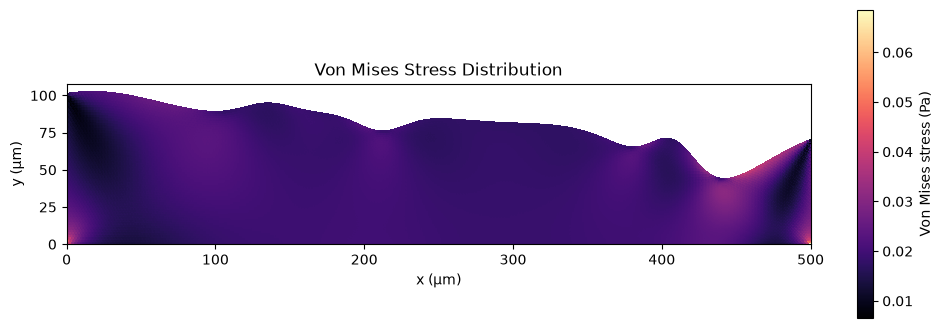

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))

plot = ax.tripcolor(
    points_um[:, 0],
    points_um[:, 1],
    triangles,
    facecolors=sigma_e,
    shading="flat",
    cmap="magma"
)

fig.colorbar(
    plot,
    ax=ax,
    label="Von Mises stress (Pa)"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Von Mises Stress Distribution")

ax.set_xlim(x.min(), x.max())
ax.set_ylim(bottom=0)
ax.set_aspect("equal")

plt.show()

## 14. Calculating the Overstressed Area Fraction

Rather than relying exclusively on maximum stress, we calculate the proportion of the biofilm's cross-sectional area exceeding an assumed effective strength threshold.

$$
f_{\mathrm{overstress}}
=
\frac{
\sum_i A_i \mathbb{1}(\sigma_{e,i}>\sigma_t)
}{
\sum_i A_i
}
$$

where:

- $A_i$ is the area of triangular element $i$.
- $\sigma_{e,i}$ is its von Mises equivalent stress.
- $\sigma_t$ is the assumed effective strength threshold.
- $\mathbb{1}$ is an indicator function equal to 1 when the condition is satisfied.

This accounts for differences in element area and provides a measure of how extensively elevated stresses are distributed throughout the biofilm.

It does not represent the fraction of biomass that has physically detached.

In [16]:
# Calculate triangle areas
P = points_m[triangles]

AB = P[:, 1] - P[:, 0]
AC = P[:, 2] - P[:, 0]

areas = 0.5 * np.abs(
    AB[:, 0] * AC[:, 1]
    - AB[:, 1] * AC[:, 0]
)

# Identify overstressed elements
overstressed = sigma_e > sigma_t

# Area-weighted fraction
overstress_fraction = (
    areas[overstressed].sum() / areas.sum()
)

print(f"Total biofilm area: {areas.sum():.6e} m²")
print(f"Overstressed area fraction: {overstress_fraction:.4%}")

Total biofilm area: 4.000000e-08 m²
Overstressed area fraction: 0.0000%


## 15. Investigating Boundary Stress Concentrations

Our biofilm is fixed along its bottom boundary:

$$
\mathbf{u}(x,0)=\mathbf{0}
$$

The left and right boundaries are traction-free, while the upper surface experiences prescribed horizontal traction.

At the bottom corners, the fixed boundary meets a traction-free boundary.

Such abrupt changes in boundary conditions can produce localized stress concentrations and, in certain elasticity problems, mathematical stress singularities.

Consequently, the maximum stress calculated near these corners may depend strongly on mesh resolution.

To investigate this, we distinguish between:

1. **Global maximum stress:** Maximum stress anywhere in the biofilm.
2. **Interior maximum stress:** Maximum stress after excluding small regions near the fixed-base corners.

The exclusion is a numerical diagnostic, not a physical modification of the biofilm.

We will subsequently test whether these stress values converge under mesh refinement.

In [18]:
# Calculate triangle centroids (μm)
P_um = points_um[triangles]

centroids = P_um.mean(axis=1)

xc = centroids[:, 0]
yc = centroids[:, 1]

# Exclude regions within 5 μm of the two bottom corners
corner_radius = 5.0

dist_left = np.sqrt(
    (xc - x.min())**2 + yc**2
)

dist_right = np.sqrt(
    (xc - x.max())**2 + yc**2
)

interior_mask = (
    (dist_left > corner_radius)
    & (dist_right > corner_radius)
)

# Compare maximum stresses
global_peak = sigma_e.max()
interior_peak = sigma_e[interior_mask].max()

print(f"Global maximum:   {global_peak:.6f} Pa")
print(f"Interior maximum: {interior_peak:.6f} Pa")

print(
    f"Difference: "
    f"{(global_peak - interior_peak) / global_peak * 100:.2f}%"
)

Global maximum:   0.068521 Pa
Interior maximum: 0.039652 Pa
Difference: 42.13%


Peak stress: 0.06852080611030903 Pa
Peak location: [499.66666667   0.78059075] μm


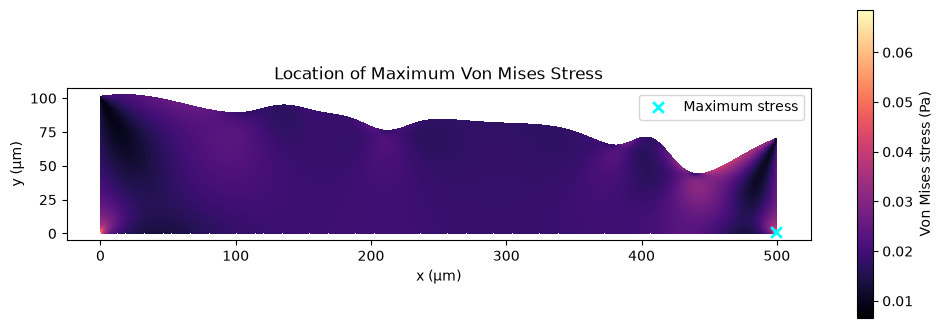

In [19]:
# Element with maximum von Mises stress
peak_idx = np.argmax(sigma_e)

print("Peak stress:", sigma_e[peak_idx], "Pa")
print("Peak location:", centroids[peak_idx], "μm")

# Visualize peak location
fig, ax = plt.subplots(figsize=(12, 4))

plot = ax.tripcolor(
    points_um[:, 0],
    points_um[:, 1],
    triangles,
    facecolors=sigma_e,
    shading="flat",
    cmap="magma"
)

ax.scatter(
    xc[peak_idx],
    yc[peak_idx],
    color="cyan",
    s=60,
    marker="x",
    linewidths=2,
    label="Maximum stress"
)

fig.colorbar(plot, ax=ax, label="Von Mises stress (Pa)")

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Location of Maximum Von Mises Stress")
ax.set_aspect("equal")
ax.legend()

plt.show()

## 16. Verifying Global Force Balance

The structural FEM solution must satisfy static mechanical equilibrium.

The total external force acting on the biofilm must be balanced by the reaction force exerted by the fixed substrate:

$$
\boxed{
\mathbf F_{\mathrm{external}}
+
\mathbf F_{\mathrm{reaction}}
=\mathbf 0
}
$$

For a uniform horizontal traction applied to the irregular upper surface:

$$
F_x=t_x\int_{\Gamma_t}ds
$$

In our two-dimensional model, this represents force per unit out-of-plane depth.

We calculate the applied force from the lengths of the upper boundary edges.

We will then compare this result against the substrate reaction forces obtained from the assembled FEM equations.

In [21]:
# Coordinates of top boundary nodes (metres)
top_nodes = boundaries["top"]

top_points = points_m[top_nodes]

# Length of each top boundary segment
edge_vectors = np.diff(top_points, axis=0)

edge_lengths = np.linalg.norm(
    edge_vectors,
    axis=1
)

# Total exposed surface length
surface_length = edge_lengths.sum()

# Applied force per unit out-of-plane depth (N/m)
F_applied_x = traction_x * surface_length
F_applied_y = traction_y * surface_length

print(f"Surface length: {surface_length / UM:.3f} μm")
print(f"Applied Fx: {F_applied_x:.6e} N/m")
print(f"Applied Fy: {F_applied_y:.6e} N/m")

Surface length: 525.282 μm
Applied Fx: 5.252825e-06 N/m
Applied Fy: 0.000000e+00 N/m


## 17. Verifying Force Balance

For a body in static equilibrium, the sum of external and reaction forces must equal zero:

$$
\boxed{
\mathbf F_{\mathrm{applied}}
+
\mathbf F_{\mathrm{reaction}}
=\mathbf 0
}
$$

The applied horizontal force per unit out-of-plane depth is:

$$
F_x^{\mathrm{applied}}
=
t_x\int_{\Gamma_t}ds
$$

The fixed substrate generates reaction forces that balance the applied traction.

In the finite-element formulation:

$$
\mathbf K\mathbf U=\mathbf F
$$

After solving for the unconstrained displacement degrees of freedom, the reaction forces at constrained degrees of freedom are obtained from:

$$
\boxed{
\mathbf R=\mathbf K\mathbf U-\mathbf F
}
$$

The global reaction force is calculated by summing the reaction components along the fixed substrate.

This provides an independent numerical verification of static equilibrium.

In [30]:
# Count how many vertices of each triangle lie on y = 0
n_base_vertices = np.sum(
    np.isclose(points_um[triangles, 1], 0, atol=1e-12),
    axis=1
)

# Triangles with an edge on the substrate
base_triangles = np.where(n_base_vertices == 2)[0]

# Sort by horizontal centroid
base_triangles = base_triangles[
    np.argsort(xc[base_triangles])
]

# Base-edge lengths
base_edges = []

for idx in base_triangles:
    tri = triangles[idx]
    nodes = tri[
        np.isclose(points_um[tri, 1], 0, atol=1e-12)
    ]
    base_edges.append(
        abs(points_m[nodes[1], 0] - points_m[nodes[0], 0])
    )

base_edges = np.asarray(base_edges)

# Integrate stresses over the substrate
R_x = -np.sum(txy[base_triangles] * base_edges)
R_y = -np.sum(syy[base_triangles] * base_edges)

print(f"Applied Fx:  {F_applied_x:.6e} N/m")
print(f"Reaction Rx: {R_x:.6e} N/m")
print(f"Balance error: {abs(R_x + F_applied_x)/abs(F_applied_x):.3%}")

Applied Fx:  5.252825e-06 N/m
Reaction Rx: -5.279396e-06 N/m
Balance error: 0.506%


## 18. Verifying the Reusable FEM Implementation

The structural FEM implementation has been consolidated into
`src/structural_fem.py`.

Before conducting additional simulations, we verify that the reusable
solver reproduces the results obtained from the original notebook.

Both implementations use identical:

- Biofilm geometry and mesh resolution.
- Material properties.
- Plane-strain formulation.
- Fixed-substrate boundary conditions.
- Prescribed surface traction.

Agreement confirms that refactoring has not changed the numerical
implementation.

This is a reproducibility check, not experimental validation.

In [32]:
from src.structural_fem import solve_biofilm

result = solve_biofilm(
    x=x,
    h=h,
    ny=60,
    E=64.0,
    nu=0.3,
    traction_x=0.01,
)

print("=== Reusable FEM Results ===")

print(
    f"Maximum displacement: "
    f"{result['max_displacement_um']:.6f} μm"
)

print(
    f"Maximum principal strain: "
    f"{result['max_principal_strain'] * 100:.4f}%"
)

print(
    f"Global maximum stress: "
    f"{result['global_peak']:.6f} Pa"
)

print(
    f"Interior maximum stress: "
    f"{result['interior_peak']:.6f} Pa"
)

print(
    f"Applied horizontal force: "
    f"{result['F_applied_x']:.6e} N/m"
)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 2.356466e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 3.168807e-19 (rel: 1.344729e-12)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
=== Reusable FEM Results ===
Maximum dis

## 19. Mesh Convergence Study

Finite-element analysis approximates a continuous displacement field using a finite number of elements.

Consequently, numerical results may depend on the mesh resolution.

To assess numerical convergence, we solve the same mechanical problem using progressively finer meshes.

The governing equations, material properties, geometry, and boundary conditions remain unchanged.

We compare:

1. Maximum von Mises stress.
2. Interior maximum von Mises stress, excluding fixed-base corners.
3. Maximum displacement.
4. Estimated force-balance error.

A numerical quantity is considered converged when further mesh refinement produces sufficiently small changes.

### Stress concentrations

Sharp corners and abrupt changes in boundary conditions may produce stress singularities.

Consequently, the global maximum stress may continue increasing under mesh refinement.

We therefore examine interior stress separately.

However, excluding corners is only a numerical diagnostic and does not establish that stresses near the biofilm–substrate interface are physically irrelevant.

In [33]:
from src.structural_fem import solve_biofilm

# Increasing mesh resolutions
resolutions = [
    (251, 30),
    (501, 60),
    (751, 90),
    (1001, 120)
]

convergence_results = []

for nx_test, ny_test in resolutions:

    # Reconstruct the SAME biofilm geometry
    x_test = np.linspace(x.min(), x.max(), nx_test)
    h_test = np.interp(x_test, x, h)

    # Solve structural FEM
    r = solve_biofilm(
        x=x_test,
        h=h_test,
        ny=ny_test,
        E=64.0,
        nu=0.3,
        traction_x=0.01
    )

    convergence_results.append({
        "nx": nx_test,
        "ny": ny_test,
        "elements": len(r["triangles"]),
        "global_peak": r["global_peak"],
        "interior_peak": r["interior_peak"],
        "max_displacement": r["max_displacement_um"]
    })

    print(
        f"nx={nx_test:4d}, ny={ny_test:3d} | "
        f"Global={r['global_peak']:.6f} Pa | "
        f"Interior={r['interior_peak']:.6f} Pa | "
        f"Displacement={r['max_displacement_um']:.6f} μm"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15060, 15060)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 206352 (9.10e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 3.330586e-07 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.03 [s]
sfepy: nls: iter: 1, residual: 1.482051e-19 (rel: 4.449820e-13)
sfepy: solved in 1 steps in 0.04 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
nx= 251, ny= 30 | Global=0.056715 Pa | I

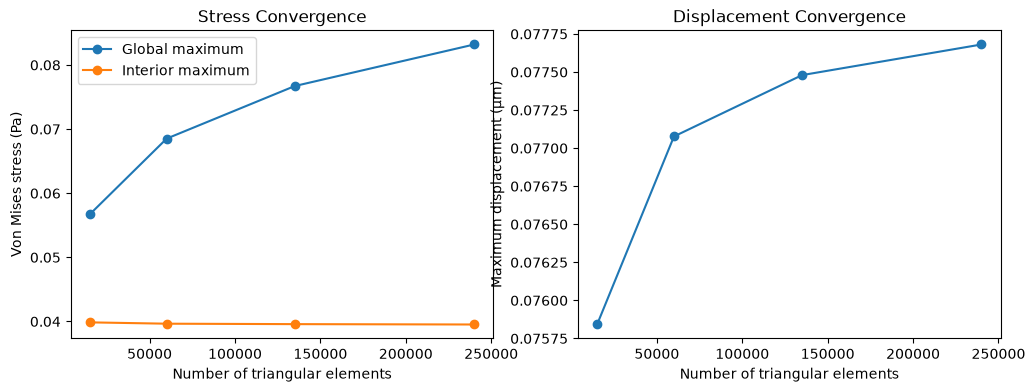

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

n_elements = [r["elements"] for r in convergence_results]

axes[0].plot(
    n_elements,
    [r["global_peak"] for r in convergence_results],
    "o-",
    label="Global maximum"
)

axes[0].plot(
    n_elements,
    [r["interior_peak"] for r in convergence_results],
    "o-",
    label="Interior maximum"
)

axes[0].set_xlabel("Number of triangular elements")
axes[0].set_ylabel("Von Mises stress (Pa)")
axes[0].set_title("Stress Convergence")
axes[0].legend()

axes[1].plot(
    n_elements,
    [r["max_displacement"] for r in convergence_results],
    "o-"
)

axes[1].set_xlabel("Number of triangular elements")
axes[1].set_ylabel("Maximum displacement (μm)")
axes[1].set_title("Displacement Convergence")

plt.show()

In [35]:
metrics = [
    "global_peak",
    "interior_peak",
    "max_displacement"
]

for metric in metrics:
    values = np.array([
        r[metric] for r in convergence_results
    ])

    relative_changes = (
        np.abs(np.diff(values)) / np.abs(values[1:])
    ) * 100

    print(f"\n{metric}")

    for i, change in enumerate(relative_changes):
        print(
            f"  Mesh {i+1} → {i+2}: "
            f"{change:.4f}%"
        )


global_peak
  Mesh 1 → 2: 17.2289%
  Mesh 2 → 3: 10.6849%
  Mesh 3 → 4: 7.7877%

interior_peak
  Mesh 1 → 2: 0.5232%
  Mesh 2 → 3: 0.1728%
  Mesh 3 → 4: 0.1437%

max_displacement
  Mesh 1 → 2: 1.6021%
  Mesh 2 → 3: 0.5200%
  Mesh 3 → 4: 0.2589%


## 18.1 Mesh Convergence Results

### Quantitative Convergence Analysis

To quantify convergence, we calculated the relative change in each
mechanical quantity between successive mesh resolutions:

$$
\delta =
\frac{|Q_{\mathrm{fine}}-Q_{\mathrm{coarse}}|}
{|Q_{\mathrm{fine}}|}
\times 100\%
$$

| Mesh refinement | Global maximum stress | Interior maximum stress | Maximum displacement |
|---|---:|---:|---:|
| Mesh 1 → 2 | 17.2289% | 0.5232% | 1.6021% |
| Mesh 2 → 3 | 10.6849% | 0.1728% | 0.5200% |
| Mesh 3 → 4 | 7.7877% | 0.1437% | 0.2589% |

**Global maximum stress:** Although the relative change decreases
with refinement, it remains relatively large at 7.79% between the
finest two meshes. This indicates that the global maximum stress
has not converged over the tested resolutions, consistent with
localized stress concentrations near the fixed-base corners.

**Interior maximum stress:** The relative change decreases to
0.1437% between the finest two meshes. This demonstrates strong
numerical stability of the interior maximum stress under the
chosen 5 μm corner-exclusion criterion.

**Maximum displacement:** The relative change decreases to
0.2589% between the finest two meshes, indicating that the
displacement solution is approaching convergence.

### Conclusion

The interior maximum stress and maximum displacement both
demonstrate relative changes below 0.3% between the finest
two meshes.

These results provide evidence of numerical convergence for
these quantities under the tested mesh resolutions.

However, the global maximum stress remains mesh-dependent.
Consequently, it should not be used independently as a
mechanical-failure indicator without further investigation
of boundary stress concentrations.

The convergence findings support proceeding with stochastic
mechanical-vulnerability analysis, while retaining mesh
sensitivity and corner-exclusion sensitivity as important
numerical limitations.